# Yield curve construction : interpolation and bootstrapping

The aim of this notebook is to present and compare the usual ways of building a zero-coupon curve,
and to provide the curve objects used later to price exotic products.

**Pipeline :**
1. Load the EURIBOR 6M zero-coupon rates (12/02/2025).
2. Compare seven interpolation methods : shape of the zero and forward curves, smoothness, locality.
3. Bootstrap a curve from market instruments (deposits, FRA, swaps), first on quotes generated from the EURIBOR curve,
   then on real US Treasury par yields.
4. Measure the risk of an off-pillar instrument (key-rate sensitivities) for each method.
5. Show how the curve is used downstream (discounting, forwards, Monte Carlo drift, Heston / Black-Scholes inputs).

**Code (package `Fixed_Income_Models`) :**
- `interpolation.py` : the interpolation methods ;
- `yield_curve.py` : the `YieldCurve` class (discount factors, zero rates, forwards, par rates, bumps) ;
- `instruments.py` : `ZeroCouponRate`, `Deposit`, `FRA`, `Swap`, `ParBond` ;
- `bootstrap.py` : the `Bootstrapper` class.

In [1]:
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from yield_curve import YieldCurve
from instruments import ZeroCouponRate, Deposit, FRA, Swap, ParBond
from bootstrap import Bootstrapper

# Plot style : recessive axes and grid, 2px lines
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "text.color": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

# One fixed color per method (the color follows the method in every chart)
METHODS = ["raw", "linear_zero", "cubic_zero", "pchip_zero", "monotone_convex", "nelson_siegel", "svensson"]
LABELS = {"raw": "Raw (log-linear DF)", "linear_zero": "Linear zero", "cubic_zero": "Cubic spline zero",
          "pchip_zero": "PCHIP zero", "monotone_convex": "Monotone convex", "nelson_siegel": "Nelson-Siegel",
          "svensson": "Svensson"}
COLORS = dict(zip(METHODS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]))
STYLES = {m: ("--" if m in ("nelson_siegel", "svensson") else "-") for m in METHODS}
EXACT = [m for m in METHODS if m not in ("nelson_siegel", "svensson")]
GREY = "#898781"

## 1. Data

EURIBOR 6M zero-coupon rates on 15 pillars from 1 week to 5 years. They are taken as continuously compounded :
$P(0,T) = e^{-r(T)\,T}$. The rates are rounded to the basis point.

The discrete forward rate between two pillars, $f^d_i = \dfrac{r_i t_i - r_{i-1} t_{i-1}}{t_i - t_{i-1}}$,
is the only forward information the data contain : every exact interpolation must reproduce it on average over each segment.

In [2]:
df_rates = pd.read_csv("../Data/EURIBOR6M_ZCRates_12022025.csv")
t, r = df_rates["Expiry"].to_numpy(), df_rates["ZCRate"].to_numpy()

tau = np.concatenate([[0.0], t])
discrete_fwd = np.diff(np.concatenate([[0.0], t * r])) / np.diff(tau)
data = pd.DataFrame({"Maturity (y)": t, "Zero rate (%)": 100 * r, "Discrete forward (%)": 100 * discrete_fwd})
data.round(3).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Maturity (y),0.02,0.250,0.50,0.75,1.00,1.25,1.50,1.75,2.00,2.50,3.00,3.50,4.00,4.50,5.00
Zero rate (%),2.68,2.640,2.51,2.39,2.33,2.28,2.26,2.25,2.24,2.25,2.26,2.27,2.28,2.29,2.30
Discrete forward (%),2.68,2.637,2.38,2.15,2.15,2.08,2.16,2.19,2.17,2.29,2.31,2.33,2.35,2.37,2.39


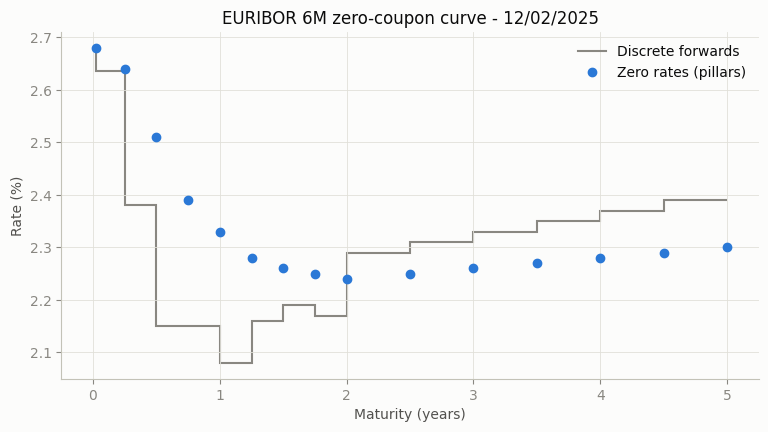

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.stairs(100 * discrete_fwd, tau, baseline=None, color=GREY, linewidth=1.5, label="Discrete forwards")
ax.plot(t, 100 * r, "o", color=COLORS["raw"], markersize=6, label="Zero rates (pillars)")
ax.set_title("EURIBOR 6M zero-coupon curve - 12/02/2025")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Rate (%)")
ax.legend()
plt.show()

The zero curve is inverted up to 2 years (expected ECB cuts) then slightly upward sloping.
The discrete forwards are much more irregular than the zero rates : a forward is a derivative of $r(T)\,T$,
so it amplifies the 1bp rounding of the data. This is the first reason why the interpolation must be judged on the forward curve.

## 2. Interpolation methods

Every method is expressed through $y(T) = r(T)\,T = -\ln P(0,T)$ ; the instantaneous forward is $f(0,T) = y'(T)$.
Outside the pillars : flat zero rate before the first pillar, flat instantaneous forward after the last one.

| Method | Interpolated quantity | Forward curve | Local | Exact |
|---|---|---|---|---|
| Raw | $\ln P$ linear | piecewise constant (steps) | yes | yes |
| Linear zero | $r$ linear | discontinuous (saw-tooth) | yes | yes |
| Cubic spline zero | $r$ natural cubic spline | smooth ($C^1$) | no | yes |
| PCHIP zero | $r$ monotone cubic Hermite | continuous ($C^0$) | almost | yes |
| Monotone convex | $f$ (Hagan-West 2006) | continuous, no spurious oscillation | almost | yes |
| Nelson-Siegel | parametric, 4 parameters | smooth | no | no (least squares) |
| Svensson | parametric, 6 parameters | smooth | no | no (least squares) |

*Local* : moving one pillar only changes the curve near that pillar. This matters for hedging :
with a non-local method, a 2-year rate move changes the value of a 4-year cash flow.

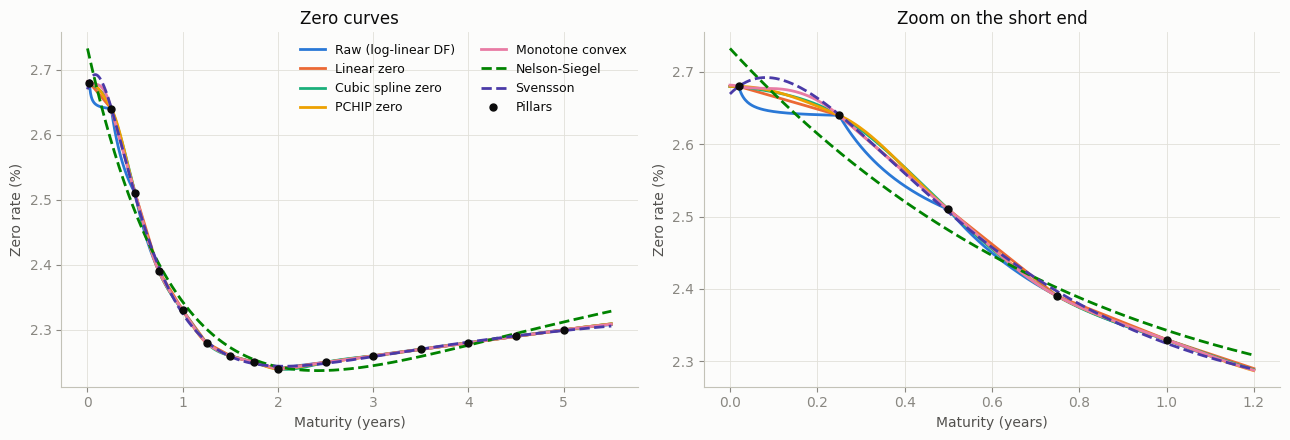

In [4]:
curves = {m: YieldCurve(t, r, m) for m in METHODS}
T_grid = np.linspace(0, 5.5, 2201)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, xmax in zip(axes, [5.5, 1.2]):
    mask = T_grid <= xmax
    for m, c in curves.items():
        ax.plot(T_grid[mask], 100 * c.zero_rate(T_grid[mask]), STYLES[m], color=COLORS[m], label=LABELS[m])
    ax.plot(t[t <= xmax], 100 * r[t <= xmax], "o", color="#0b0b0b", markersize=5, label="Pillars", zorder=5)
    ax.set_xlabel("Maturity (years)")
    ax.set_ylabel("Zero rate (%)")
axes[0].set_title("Zero curves")
axes[1].set_title("Zoom on the short end")
axes[0].legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

On the zero rates the exact methods are almost indistinguishable : they all go through the pillars and differ by a fraction
of a basis point in between. The parametric curves miss the pillars (Nelson-Siegel by up to 5bp at the short end).
The forward curve reveals the differences :

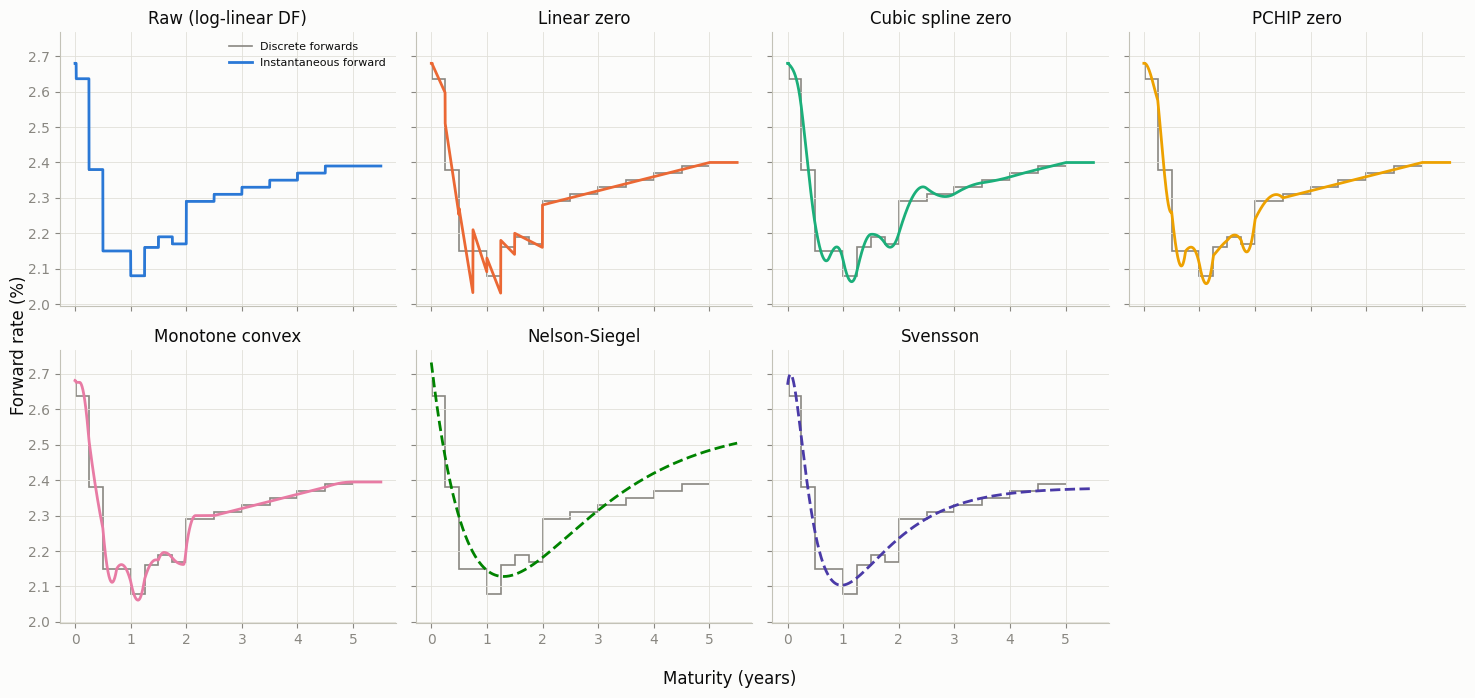

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
for ax, m in zip(axes.flat, METHODS):
    ax.stairs(100 * discrete_fwd, tau, baseline=None, color=GREY, linewidth=1.2, label="Discrete forwards")
    ax.plot(T_grid, 100 * curves[m].instantaneous_forward(T_grid), STYLES[m], color=COLORS[m], label="Instantaneous forward")
    ax.set_title(LABELS[m])
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=8, loc="upper right")
fig.supxlabel("Maturity (years)")
fig.supylabel("Forward rate (%)")
plt.tight_layout()
plt.show()

- **Raw** : the forward is exactly the discrete forward, a step function.
- **Linear zero** : saw-tooth forwards, with a jump at every pillar.
- **Cubic spline / PCHIP** : smooth zero rates, but the forward $f = r + T\,r'$ overshoots the discrete forwards.
- **Monotone convex** : continuous forward which stays within the range of the neighbouring discrete forwards.
- **Nelson-Siegel / Svensson** : very smooth, but they average the data instead of reproducing it.

### 2.1 Quantitative comparison

- *Pillar error* : largest gap between the curve and the input zero rates.
- *Forward jump* : largest discontinuity of $f$ at an inner pillar.
- *Forward total variation* : $\sum |\Delta f|$ over a fine grid on $[0, 5]$, a measure of how much the forward curve oscillates
  (the discrete forwards themselves give the reference value).
- *Locality* : the 2-year zero rate is bumped by +1bp ; largest forward change far from it (outside $[1.5, 3]$ years).

In [6]:
T_fine = np.linspace(0, 5, 5001)
inner = t[1:-1]
i2y = int(np.where(np.isclose(t, 2.0))[0][0])
far = (T_fine < 1.5) | (T_fine > 3.0)
fd_tv = 1e4 * np.sum(np.abs(np.diff(discrete_fwd)))

rows = []
for m, c in curves.items():
    f = c.instantaneous_forward(T_fine)
    jumps = c.instantaneous_forward(inner + 1e-7) - c.instantaneous_forward(inner - 1e-7)
    df_bump = c.bumped(i2y, 1.0).instantaneous_forward(T_fine) - f
    start = time.perf_counter()
    for _ in range(50):
        c.discount(T_fine)
    rows.append({"Method": LABELS[m],
                 "Pillar error (bp)": 1e4 * np.max(np.abs(c.zero_rate(t) - r)),
                 "Max forward jump (bp)": 1e4 * np.max(np.abs(jumps)),
                 "Forward total variation (bp)": 1e4 * np.sum(np.abs(np.diff(f))),
                 "Forward min (%)": 100 * f.min(), "Forward max (%)": 100 * f.max(),
                 "2y bump : max |df| (bp)": 1e4 * np.max(np.abs(df_bump)),
                 "2y bump : max |df| far (bp)": 1e4 * np.max(np.abs(df_bump[far])),
                 "Time (us / point)": 1e6 * (time.perf_counter() - start) / 50 / len(T_fine)})
comparison = pd.DataFrame(rows).set_index("Method")
print(f"Total variation of the discrete forwards (reference) : {fd_tv:.1f} bp")
comparison.round(3)

Total variation of the discrete forwards (reference) : 95.0 bp


,Pillar error (bp),Max forward jump (bp),Forward total variation (bp),Forward min (%),Forward max (%),2y bump : max |df| (bp),2y bump : max |df| far (bp),Time (us / point)
Method,,,,,,,,
Raw (log-linear DF),0.000,25.652,95.000,2.080,2.680,8.000,0.000,0.016
Linear zero,0.000,18.000,165.376,2.030,2.680,8.992,0.000,0.018
Cubic spline zero,0.000,0.000,115.948,2.063,2.680,9.456,1.827,0.024
PCHIP zero,0.000,0.000,118.737,2.058,2.680,10.265,0.000,0.023
Monotone convex,0.000,0.000,112.207,2.061,2.682,9.762,0.000,0.168
Nelson-Siegel,5.072,0.000,96.044,2.128,2.732,0.740,0.740,0.034
Svensson,0.648,0.000,89.624,2.103,2.699,0.651,0.651,0.052


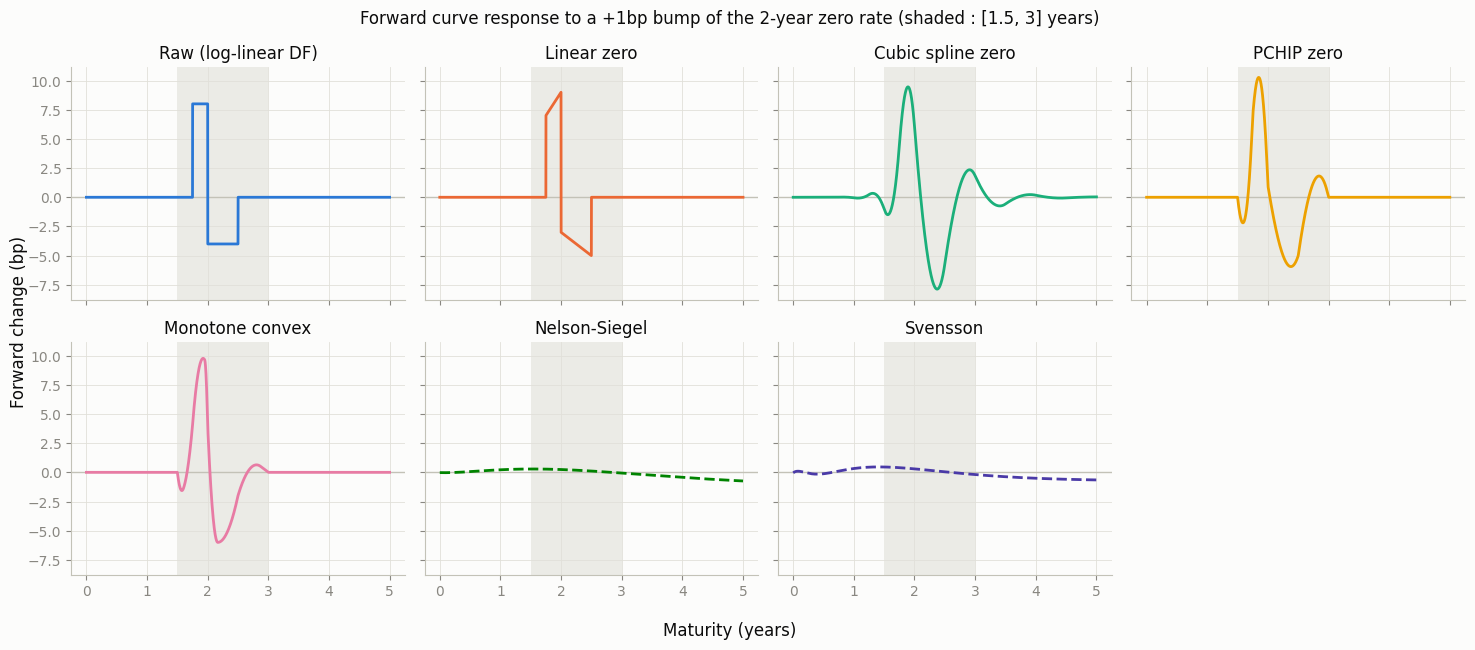

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True, sharey=True)
for ax, m in zip(axes.flat, METHODS):
    c = curves[m]
    df_bump = c.bumped(i2y, 1.0).instantaneous_forward(T_fine) - c.instantaneous_forward(T_fine)
    ax.axvspan(1.5, 3.0, color="#e1e0d9", alpha=0.6, linewidth=0)
    ax.axhline(0, color="#c3c2b7", linewidth=1)
    ax.plot(T_fine, 1e4 * df_bump, STYLES[m], color=COLORS[m])
    ax.set_title(LABELS[m])
axes.flat[-1].axis("off")
fig.supxlabel("Maturity (years)")
fig.supylabel("Forward change (bp)")
fig.suptitle("Forward curve response to a +1bp bump of the 2-year zero rate (shaded : [1.5, 3] years)")
plt.tight_layout()
plt.show()

Raw, linear zero, PCHIP and monotone convex keep the bump within $[1.5, 3]$ years ; the natural cubic spline propagates it
along the whole curve (up to 1.8bp of forward change outside that window, with alternating signs), and the parametric curves
spread it everywhere since they refit all their parameters.

Among the exact methods, raw has the lowest forward total variation (it is the data itself) but a step forward ;
monotone convex has the lowest variation of the continuous methods (112bp against 116 for the cubic spline, 119 for PCHIP
and 165 for linear zero). It is the only method combining exact pillars, a continuous forward and locality,
which is why it is a market standard (Hagan & West, 2006).

### 2.2 Parametric curves

Nelson-Siegel and Svensson describe the whole curve with a few interpretable parameters
(level $\beta_0$, slope $\beta_1$, curvature $\beta_2$, $\beta_3$ and decays $\lambda$) :
$$
r(T) = \beta_0 + \beta_1 \frac{1 - e^{-T/\lambda_1}}{T/\lambda_1}
+ \beta_2 \left(\frac{1 - e^{-T/\lambda_1}}{T/\lambda_1} - e^{-T/\lambda_1}\right)
+ \beta_3 \left(\frac{1 - e^{-T/\lambda_2}}{T/\lambda_2} - e^{-T/\lambda_2}\right)
$$
($\beta_3 = 0$ for Nelson-Siegel). Given the $\lambda$'s the betas are linear, so they are fitted by least squares
and the $\lambda$'s by a low-dimensional search. They are used by central banks and for smoothing, not for pricing :
they do not reprice the inputs.

In [8]:
params = pd.DataFrame({LABELS[m]: curves[m].interpolator.params for m in ["nelson_siegel", "svensson"]}).T
residuals = pd.DataFrame({LABELS[m]: 1e4 * (curves[m].zero_rate(t) - r) for m in ["nelson_siegel", "svensson"]}, index=t).T
print("Fitted parameters :")
display(params.round(5))
print("Residuals at the pillars (bp) :")
residuals.round(2)

Fitted parameters :


,beta0,beta1,beta2,lambda1,beta3,lambda2
Nelson-Siegel,0.02556,0.00176,-0.01329,1.14782,NaN,NaN
Svensson,0.02379,0.00291,0.00781,0.19678,-0.00883,0.69563


Residuals at the pillars (bp) :


,0.02,0.25,0.50,0.75,1.00,1.25,1.50,1.75,2.00,2.50,3.00,3.50,4.00,4.50,5.00
Nelson-Siegel,3.95,-5.07,-2.85,1.14,1.29,2.13,1.27,0.41,0.32,-1.25,-1.51,-1.09,-0.37,0.44,1.20
Svensson,-0.01,0.10,-0.37,0.65,-0.52,0.23,-0.10,-0.22,0.41,-0.16,-0.12,0.04,0.12,0.07,-0.12


## 3. Bootstrapping

In practice the curve is not given as zero rates but implied from quoted instruments. Single-curve pricing equations
(year fractions, no day count or settlement lag) :

| Instrument | Quote | Pricing equation |
|---|---|---|
| Deposit | simple rate $R$ | $1 + R\,T = 1 / P(0,T)$ |
| FRA $[T_1, T_2]$ | simple forward $R$ | $1 + R\,(T_2 - T_1) = P(0,T_1) / P(0,T_2)$ |
| Swap / par bond | par rate $S$ | $S \sum_i \delta_i P(0,t_i) = 1 - P(0,T)$ |

One pillar is placed at each instrument maturity ; the unknowns are the zero rates at the pillars.
1. **Sequential bootstrap** : with raw interpolation the curve up to $T_k$ only depends on the first $k$ pillars,
   so each instrument is solved in turn with a 1D root search.
2. **Simultaneous solve** : with a non-local interpolation (splines, monotone convex), a new pillar also changes the curve
   before the previous ones, so the $n$ equations are solved together (`scipy.optimize.root`), starting from the raw solution.

### 3.1 Round trip on the EURIBOR curve

Market quotes are generated from the monotone convex EURIBOR curve : 1M, 3M and 6M deposits, a 6x12 FRA, a 1.5-year
semi-annual swap and 2 to 5-year annual swaps. The curve is then bootstrapped back from these 9 quotes only.

In [9]:
reference = curves["monotone_convex"]
quotes = [Deposit(1/12, 0), Deposit(0.25, 0), Deposit(0.5, 0), FRA(0.5, 1.0, 0), Swap(1.5, 0, frequency=2)] \
         + [Swap(T, 0, frequency=1) for T in [2, 3, 4, 5]]
for q in quotes:
    q.quote = q.implied_quote(reference)

bootstrapped, rows = {}, []
T_cmp = np.linspace(0.01, 5, 2000)
for m in EXACT:
    bootstrapper = Bootstrapper(quotes, method=m)
    bootstrapped[m] = bootstrapper.run()
    rows.append({"Method": LABELS[m], "Solver": bootstrapper.solver,
                 "Max quote residual (bp)": bootstrapper.max_residual_bp,
                 "Time (ms)": 1000 * bootstrapper.elapsed,
                 "Max |zero - reference| (bp)": 1e4 * np.max(np.abs(bootstrapped[m].zero_rate(T_cmp) - reference.zero_rate(T_cmp))),
                 "Max |forward - reference| (bp)": 1e4 * np.max(np.abs(bootstrapped[m].instantaneous_forward(T_cmp)
                                                                      - reference.instantaneous_forward(T_cmp)))})
print("Quotes :")
display(bootstrapper.report().round(4))
pd.DataFrame(rows).set_index("Method").round(4)

Quotes :


,instrument,maturity,quote (%),implied (%),residual (bp),zero rate (%)
0,deposit,0.0833,2.6803,2.6803,0.0,2.6774
1,deposit,0.2500,2.6487,2.6487,0.0,2.6400
2,deposit,0.5000,2.5258,2.5258,0.0,2.5100
3,FRA,1.0000,2.1616,2.1616,0.0,2.3300
4,swap,1.5000,2.2743,2.2743,0.0,2.2600
5,swap,2.0000,2.2663,2.2663,0.0,2.2400
6,swap,3.0000,2.2860,2.2860,0.0,2.2600
7,swap,4.0000,2.3057,2.3057,0.0,2.2800
8,swap,5.0000,2.3253,2.3253,0.0,2.3000


,Solver,Max quote residual (bp),Time (ms),Max |zero - reference| (bp),Max |forward - reference| (bp)
Method,,,,,
Raw (log-linear DF),sequential,0.0,7.8034,2.1629,13.1008
Linear zero,simultaneous (hybr),0.0,14.0219,3.0391,14.4759
Cubic spline zero,simultaneous (hybr),0.0,17.4983,1.0011,5.3732
PCHIP zero,simultaneous (hybr),0.0,17.8170,1.6661,7.3676
Monotone convex,simultaneous (hybr),0.0,47.4014,0.8300,5.8388


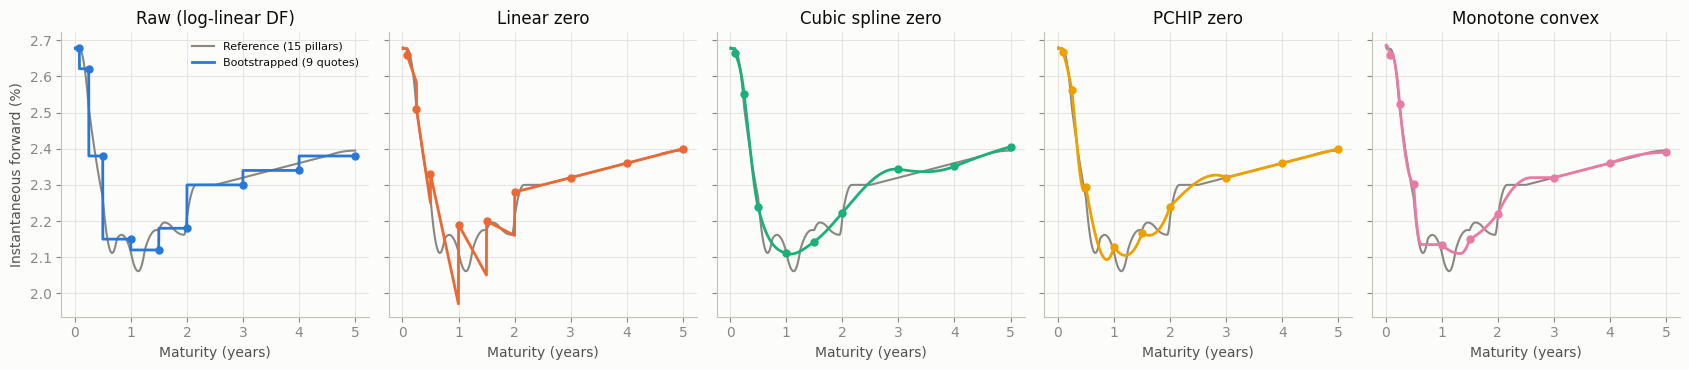

In [10]:
fig, axes = plt.subplots(1, len(EXACT), figsize=(17, 3.8), sharey=True)
for ax, m in zip(axes, EXACT):
    ax.plot(T_cmp, 100 * reference.instantaneous_forward(T_cmp), color=GREY, linewidth=1.5, label="Reference (15 pillars)")
    ax.plot(T_cmp, 100 * bootstrapped[m].instantaneous_forward(T_cmp), color=COLORS[m], label="Bootstrapped (9 quotes)")
    ax.plot([q.maturity for q in quotes], 100 * bootstrapped[m].instantaneous_forward([q.maturity for q in quotes]),
            "o", color=COLORS[m], markersize=5)
    ax.set_title(LABELS[m])
    ax.set_xlabel("Maturity (years)")
axes[0].set_ylabel("Instantaneous forward (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Every method reprices the 9 quotes to machine precision, yet the curves differ between the pillars : with 9 quotes instead of
15 pillars, the zero rates are recovered within 1 to 3bp and the forwards much less accurately.
The interpolation is a modelling assumption : the market only pins down the instruments, not what happens in between.

### 3.2 Real market data : US Treasury par yields

Daily US Treasury par yield curve (bills up to 1 year, then coupon securities up to 30 years), latest date of the file.
Simplifications : bills up to 6 months are treated as simple-rate zero coupons, the 1-year bill as a semi-annual zero coupon,
and notes/bonds as semi-annual par bonds.

In [11]:
treasury = pd.read_csv("../Bermudan Swaption/daily-treasury-rates.csv", parse_dates=["Date"]).sort_values("Date")
TENORS = {"1 Mo": 1/12, "1.5 Month": 1.5/12, "2 Mo": 2/12, "3 Mo": 0.25, "4 Mo": 4/12, "6 Mo": 0.5, "1 Yr": 1.0,
          "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0, "30 Yr": 30.0}

def treasury_instruments(row):
    instruments = []
    for column, T in TENORS.items():
        if pd.isna(row[column]):
            continue
        y = row[column] / 100
        if T <= 0.5:
            instruments.append(ZeroCouponRate(T, y, compounding='simple'))
        elif T == 1.0:
            instruments.append(ZeroCouponRate(T, y, compounding=2))
        else:
            instruments.append(ParBond(T, y, frequency=2))
    return instruments

last = treasury.iloc[-1]
print(f"Date : {last['Date'].date()} ({len(treasury)} dates in the file)")
treasury_curves = {}
for m in ["raw", "cubic_zero", "monotone_convex"]:
    bootstrapper = Bootstrapper(treasury_instruments(last), method=m)
    treasury_curves[m] = bootstrapper.run()
    print(f"{LABELS[m]:18s} max residual {bootstrapper.max_residual_bp:.1e} bp, {1000 * bootstrapper.elapsed:.0f} ms")
bootstrapper.report().round(4)

Date : 2026-09-21 (181 dates in the file)
Raw (log-linear DF) max residual 3.5e-13 bp, 15 ms
Cubic spline zero  max residual 2.8e-13 bp, 71 ms
Monotone convex    max residual 3.5e-13 bp, 111 ms


,instrument,maturity,quote (%),implied (%),residual (bp),zero rate (%)
0,zero-coupon,0.0833,3.96,3.96,0.0,3.9535
1,zero-coupon,0.1250,4.02,4.02,0.0,4.0099
2,zero-coupon,0.1667,4.10,4.10,0.0,4.0861
3,zero-coupon,0.2500,4.17,4.17,0.0,4.1484
4,zero-coupon,0.3333,4.26,4.26,0.0,4.2300
5,zero-coupon,0.5000,4.27,4.27,0.0,4.2251
6,zero-coupon,1.0000,4.45,4.45,0.0,4.4012
7,par bond,2.0000,4.76,4.76,-0.0,4.7126
8,par bond,3.0000,4.82,4.82,-0.0,4.7713
9,par bond,5.0000,4.83,4.83,-0.0,4.7784


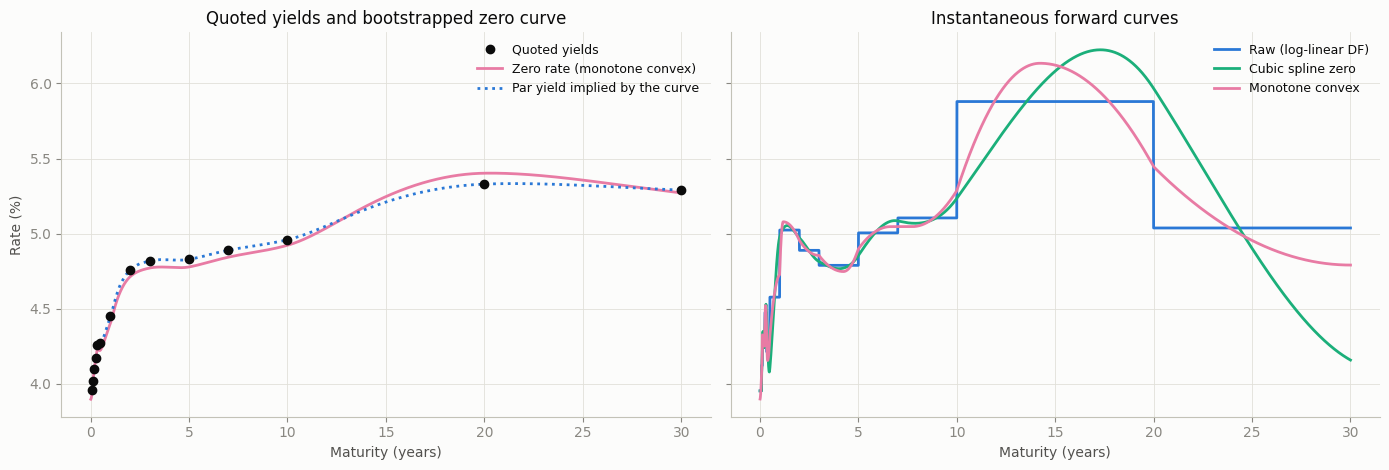

In [12]:
T_us = np.linspace(0.01, 30, 3000)
maturities = [inst.maturity for inst in treasury_instruments(last)]
par_yields = [inst.quote for inst in treasury_instruments(last)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
axes[0].plot(maturities, 100 * np.array(par_yields), "o", color="#0b0b0b", markersize=6, label="Quoted yields", zorder=5)
axes[0].plot(T_us, 100 * treasury_curves["monotone_convex"].zero_rate(T_us), color=COLORS["monotone_convex"],
             label="Zero rate (monotone convex)")
axes[0].plot(T_us, 100 * np.array([treasury_curves["monotone_convex"].par_rate(T, 2) if T >= 0.5 else np.nan for T in T_us]),
             ":", color=COLORS["raw"], label="Par yield implied by the curve")
axes[0].set_title("Quoted yields and bootstrapped zero curve")
for m in ["raw", "cubic_zero", "monotone_convex"]:
    axes[1].plot(T_us, 100 * treasury_curves[m].instantaneous_forward(T_us), color=COLORS[m], label=LABELS[m])
axes[1].set_title("Instantaneous forward curves")
for ax in axes:
    ax.set_xlabel("Maturity (years)")
    ax.legend(fontsize=9)
axes[0].set_ylabel("Rate (%)")
plt.tight_layout()
plt.show()

All methods reprice the 14 quotes exactly, but with sparse long-end quotes (7, 10, 20, 30 years) the forward curves diverge :
- raw : the forward drops by 0.84% at 20 years (5.88% on 10-20y, 5.04% on 20-30y) ;
- over 10-20y, the forward at both ends is below the segment's average forward, so every continuous method must rise above
  it in the middle : monotone convex peaks at 6.1%, the cubic spline at 6.2% ;
- beyond 20 years the cubic spline dives to 4.2% at 30 years, below every quote, while monotone convex stays around 4.8%.

Long-dated forwards, which drive long-dated exotics, are therefore largely a product of the interpolation choice.

### 3.3 Curve history and principal components

The Treasury curve is bootstrapped (monotone convex) on every date of the file ; daily zero-rate changes on a fixed maturity grid
are then decomposed in principal components. The first components are the classic level, slope and curvature factors,
the building blocks of multi-factor short-rate models.

181 curves bootstrapped in 20.8s


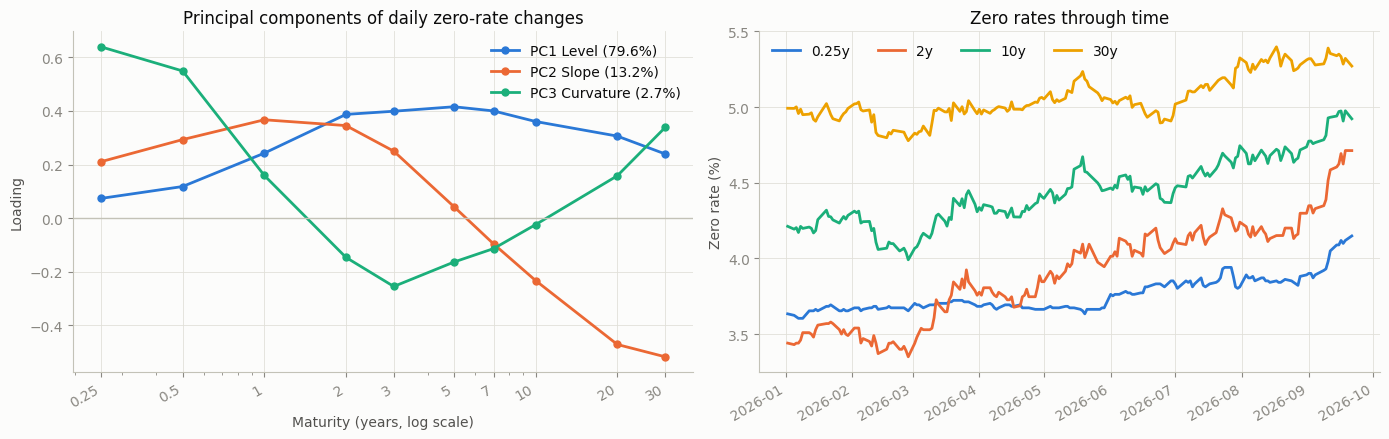

Explained variance : PC1 79.6%, PC2 13.2%, PC3 2.7%, PC4 1.4%


In [13]:
grid_pca = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
start = time.time()
history = pd.DataFrame([Bootstrapper(treasury_instruments(row), method="monotone_convex").run().zero_rate(grid_pca)
                        for _, row in treasury.iterrows()], index=treasury["Date"], columns=grid_pca)
print(f"{len(history)} curves bootstrapped in {time.time() - start:.1f}s")

changes = 1e4 * history.diff().dropna()                      # daily changes in bp
eigval, eigvec = np.linalg.eigh(np.cov(changes.to_numpy().T))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
explained = eigval / eigval.sum()
eigvec = eigvec * np.sign(eigvec.sum(axis=0))                 # sign convention : positive average loading

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for k, name in enumerate(["Level", "Slope", "Curvature"]):
    axes[0].plot(grid_pca, eigvec[:, k], "o-", color=list(COLORS.values())[k], markersize=5,
                 label=f"PC{k + 1} {name} ({100 * explained[k]:.1f}%)")
axes[0].axhline(0, color="#c3c2b7", linewidth=1)
axes[0].set_xscale("log")
axes[0].set_xticks(grid_pca, [f"{g:g}" for g in grid_pca])
axes[0].set_title("Principal components of daily zero-rate changes")
axes[0].set_xlabel("Maturity (years, log scale)")
axes[0].set_ylabel("Loading")
axes[0].legend()
for T, color in zip([0.25, 2, 10, 30], list(COLORS.values())):
    axes[1].plot(history.index, 100 * history[T], color=color, label=f"{T:g}y")
axes[1].set_title("Zero rates through time")
axes[1].set_ylabel("Zero rate (%)")
axes[1].legend(ncol=4)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print("Explained variance :", ", ".join(f"PC{k + 1} {100 * e:.1f}%" for k, e in enumerate(explained[:4])))

## 4. Risk : key-rate sensitivities of an off-pillar cash flow

A zero-coupon bond paying 1,000,000 in 3.5 years (between the 3y and 4y swap pillars) is priced on the curve
bootstrapped from the 9 EURIBOR quotes. Each quote is bumped by +1bp in turn, the curve is re-bootstrapped and the bond repriced :
the result is the bond's sensitivity to each hedging instrument. The interpolation decides which instruments hedge the bond.

In [14]:
notional, maturity = 1_000_000, 3.5

def bond_value(method, bumps_bp=None):
    # Value of the bond on the curve bootstrapped from the quotes, each quote shifted by bumps_bp[k] basis points
    bumped_quotes = copy.deepcopy(quotes)
    for q, bp in zip(bumped_quotes, bumps_bp if bumps_bp is not None else [0.0] * len(quotes)):
        q.quote += bp * 1e-4
    return notional * Bootstrapper(bumped_quotes, method=method).run().discount(maturity)

krd = {}
for m in EXACT:
    base = bond_value(m)
    sens = [bond_value(m, np.eye(len(quotes))[k]) - base for k in range(len(quotes))]
    krd[LABELS[m]] = sens + [sum(sens), bond_value(m, np.ones(len(quotes))) - base]
names = [f"{q.kind} {q.maturity:g}y" for q in quotes]
krd = pd.DataFrame(krd, index=names + ["Sum of key rates", "Parallel +1bp"]).T
print(f"Sensitivity of a {notional:,.0f} zero-coupon bond maturing in {maturity}y to a +1bp bump of each quote (EUR) :")
krd.round(2)

Sensitivity of a 1,000,000 zero-coupon bond maturing in 3.5y to a +1bp bump of each quote (EUR) :


,deposit 0.0833333y,deposit 0.25y,deposit 0.5y,FRA 1y,swap 1.5y,swap 2y,swap 3y,swap 4y,swap 5y,Sum of key rates,Parallel +1bp
Raw (log-linear DF),0.00,0.00,1.05,1.05,0.00,4.19,-135.35,-186.94,0.00,-315.99,-315.93
Linear zero,0.00,0.00,1.07,1.07,0.00,4.28,-158.84,-163.58,0.00,-316.01,-315.94
Cubic spline zero,-0.43,1.67,2.11,5.07,-30.02,63.92,-197.98,-184.78,24.20,-316.23,-316.17
PCHIP zero,0.00,0.00,1.04,1.04,0.00,31.43,-165.38,-201.46,16.48,-316.84,-315.94
Monotone convex,0.00,0.00,1.05,1.05,0.00,15.87,-186.33,-238.83,28.99,-378.22,-315.94


The parallel sensitivity is the same for every method (-316 EUR per bp, i.e. about $3.5 \times P(0, 3.5) \times 100$),
but its split across instruments is not :
- raw and linear zero : the bond is hedged by the 3y and 4y swaps only (plus a small annuity effect on shorter instruments) ;
- cubic spline : part of the risk leaks onto the 1.5y, 2y and 5y swaps, with alternating signs ;
- monotone convex : the key rates **do not add up** to the parallel sensitivity (-378 against -316 EUR).

The last point is not a numerical error. Between 2 and 5 years the EURIBOR rates increase by exactly 2bp a year, so the
discrete forwards are nearly equal and the monotone convex corrections $g_0, g_1$ are tiny (about 2bp) ; a 1bp bump moves them
across the boundaries of the Hagan-West regions. The curve stays continuous in its inputs but becomes strongly non-linear,
so the sensitivity depends on the size and sign of the bump :

In [15]:
rows = []
for m in ["raw", "pchip_zero", "monotone_convex"]:
    base = bond_value(m)
    for k in [6, 7]:                                      # 3y and 4y swaps
        row = {"Method": LABELS[m], "Quote bumped": names[k]}
        for bp in [1.0, 0.1, -0.1, -1.0]:
            row[f"{bp:+g}bp"] = (bond_value(m, bp * np.eye(len(quotes))[k]) - base) / bp
        rows.append(row)
print("Bond sensitivity per bp (EUR) for different bump sizes :")
pd.DataFrame(rows).set_index(["Method", "Quote bumped"]).round(2)

Bond sensitivity per bp (EUR) for different bump sizes :


+1bp  +0.1bp  -0.1bp    -1bp
Method              Quote bumped                                
Raw (log-linear DF) swap 3y      -135.35 -135.35 -135.35 -135.35
                    swap 4y      -186.94 -186.94 -186.94 -186.94
PCHIP zero          swap 3y      -165.38 -177.47 -180.53 -195.27
                    swap 4y      -201.46 -186.01 -182.83 -170.35
Monotone convex     swap 3y      -186.33 -152.68 -152.68 -110.68
                    swap 4y      -238.83 -210.86 -210.86 -140.57

With raw interpolation the sensitivity is identical whatever the bump (the curve is linear in the pillar rates).
PCHIP is mildly non-linear (-165 to -195 EUR per bp on the 3y swap) since its slopes are harmonic means of the neighbouring ones ;
monotone convex strongly so (-111 to -186 EUR on the 3y swap, -141 to -239 EUR on the 4y swap).
For hedging this is a real drawback : key-rate risks must then be computed with a documented bump size (or a parallel bump),
and a local and linear method such as raw may be preferred for the risk engine.

A hedge computed with one interpolation is not a hedge under another : the method must be fixed once for pricing and risk.

## 5. Using the curve downstream

`YieldCurve` gathers what pricing models need. It is callable, `curve(T)` returning the continuously compounded zero rate,
so it can be passed directly as the `zc_rate` argument of `ForwardCurve`, `BlackScholes` or `HestonModel`.

In [16]:
curve = curves["monotone_convex"]
T1, T2 = 1.0, 1.5
print(f"Zero rate r(2y)                     : {100 * curve(2.0):.4f}%  (annual compounding {100 * curve.zero_rate(2.0, 1):.4f}%)")
print(f"Discount factor P(0, 2y)            : {curve.discount(2.0):.6f}")
print(f"Simple forward {T1:g}y x {T2:g}y (FRA)      : {100 * curve.forward_rate(T1, T2, compounding='simple'):.4f}%")
print(f"Instantaneous forward f(0, 2y)      : {100 * curve.instantaneous_forward(2.0):.4f}%")
print(f"5y annual par swap rate             : {100 * curve.par_rate(5.0, frequency=1):.4f}%")
print(f"Monte Carlo drift over [1y, 1.5y]   : int f(0,s) ds = {curve.integrated_short_rate(T1, T2):.6f}")
print(f"Vectorised                          : {np.round(100 * curve.zero_rate(np.array([0.5, 1, 2, 5])), 4)}")
print(f"Parallel +10bp scenario r(2y)       : {100 * curve.shifted(10)(2.0):.4f}%")

Zero rate r(2y)                     : 2.2400%  (annual compounding 2.2653%)
Discount factor P(0, 2y)            : 0.956189
Simple forward 1y x 1.5y (FRA)      : 2.1313%
Instantaneous forward f(0, 2y)      : 2.2100%
5y annual par swap rate             : 2.3253%
Monte Carlo drift over [1y, 1.5y]   : int f(0,s) ds = 0.010600
Vectorised                          : [2.51 2.33 2.24 2.3 ]
Parallel +10bp scenario r(2y)       : 2.3400%


## 6. Conclusions and limitations

- The interpolation must be judged on the **forward curve**, not on the zero curve : methods that look identical on zero rates
  produce step, saw-tooth or oscillating forwards.
- **Monotone convex** is the best compromise for pricing : exact at the pillars, continuous forward, local, lowest forward
  variation among the continuous methods. Its drawback is risk : it is strongly non-linear in its inputs when discrete forwards
  are nearly equal, so key-rate sensitivities depend on the bump size.
- **Raw** remains the simplest, local and linear choice, well suited to a risk engine, at the cost of a step forward curve.
  Natural cubic splines are smooth but non-local and overshoot at the long end : they should not be used for risk.
- **Bootstrapping** reprices the instruments exactly with any exact interpolation, but the curve between pillars, and therefore the
  hedge of an off-pillar cash flow, depends on the method.

**Limitations of the current implementation :**
- single-curve : the same curve discounts and projects. Since 2008, swaps are priced with an OIS (€STR / SOFR) discount curve and
  a separate projection curve per tenor (EURIBOR 3M, 6M) ;
- no day-count conventions, business-day calendars or settlement lags : times are plain year fractions ;
- the EURIBOR data are assumed to be continuously compounded zero rates ; the Treasury bills are treated with a simplified convention ;
- no futures (and their convexity adjustment) among the instruments.

**Next steps :** multi-curve bootstrap (€STR discounting, EURIBOR projection), then short-rate models calibrated on this curve
(Hull-White : $\theta(t)$ fitted to the instantaneous forward curve), used to price callable and path-dependent products.